# The Nature 2024 dataset: what it holds for a moment estimator, and whether to switch to it

Raw data for **Molinaro, Scherpereel, Schonhaut, Evangelopoulos, Shepherd & Young, _Task-agnostic exoskeleton
control via biological joint moment estimation_** (*Nature* 635, 2024), dataset
[doi:10.35090/gatech/75759](https://doi.org/10.35090/gatech/75759), **Complete** variant: every recording is a
whole base task, with the stretches between conditions kept and an activity flag marking when the task is
happening. It sits in `data/nature/phase1-2` (the paper's training participants) and `data/nature/phase3`
(its validation participants).

The question for this project: can it serve as the data repository for a **hip joint-moment estimator**
(a fallback controller) and a **joint-moment forecaster**, and is it worth switching from the *Science
Robotics* 2024 dataset used so far (`data/molinaro-raw`, the 20-participant study pool)? The four things the
repository needs per sample are the **hip encoder**, the **thigh IMU**, a **task label**, and the **hip joint
moment**. Every section below asks what the data gives for one of those, and what that means for modelling;
section 7 sets the two datasets side by side.

Conventions in this notebook: moments in Nm/kg and **extension positive** (the exo's and the previous dataset's
convention; the Nature OpenSim files are flexion positive and are negated here), angles in degrees, angular
rates in deg/s. Data access lives in [`ml/nature/nature_data.py`](../../../ml/nature/nature_data.py) (checked by `test_nature_data.py`), the
dataset-agnostic helpers in [`ml/common/signals.py`](../../../ml/common/signals.py); it copies the
needed columns into a Parquet cache under `data/cache/nature/` on the first run.

## Findings at a glance

- **Complete and verified.** 22 people (25 sessions; BT01, BT02 and BT13 recorded twice), 1,358 recordings,
  26.1 hours, 26 tasks. Every published file is on disk byte for byte. BT04 was never published.
- **All four needs are covered.** Hip encoder and thigh IMU are valid in 99.3–99.9% of samples, every recording has
  a per-leg activity flag and a base-task label, and net *and* biological hip moments are valid in 99.4% of in-task
  samples (84% of all samples).
- **The build has to handle four things.**
  1. Recompute encoder velocity from the angle: the published channel is half scale for 19 of 22 sessions (3.3).
  2. The IMU axes are named differently from the previous exo: pipeline `(x, y, z)` = Nature `(y, z, x)`, no sign
     flips. The IMUs are also mounted about 5° off the anatomical axes versus 11–26° on the previous exo, so pooling
     the two datasets needs a per-participant rotation (3.4).
  3. The Complete names drop condition labels. Stair direction (100% agreement) and incline direction are
     recoverable from joint power; speed is not (4.3).
  4. "Flag off" means rest, a treadmill condition change, or walking off the force plates, depending on the task;
     only the first two have moments (4.2).
- **Net versus biological moment matters only where the exo pushed.** The difference is about 12% of peak moment in
  powered Phase 1–2 recordings, 17% in Phase 3, and under 1% in the 409 unpowered Phase 1 recordings; measured
  torque tells them apart. Moments are zero-phase filtered at 6 Hz (5.2–5.3).
- **Benchmark to beat.** The paper's own estimator, with more sensors than this project will use, reaches
  0.16 Nm/kg RMSE and R² 0.82 per participant on Phase 3. It is weakest on standing poses, stairs, sit-to-stand
  and tug of war (5.5).
- **Forecasting is a different problem beyond about 100 ms.** The moment moves about 0.4–0.5 of its spread in
  50 ms and more than its spread by 200 ms in every cyclic task (6.1).
- **Against the previous dataset:** about 4× the 1 s windows (1.84 M vs 0.42 M; 1.57 M vs 0.35 M with a moment
  label), 26 tasks instead of 7, stairs labelled on 92% of samples instead of about 35%, and level walking that
  looks alike on both exos (7).
- **Verdict:** switching is feasible and pays off for a moment estimator and forecaster. The cost is a one-time
  build (velocity, axis order, condition recovery, per-leg masks) and, unless IMU frames are rotated, losing direct
  comparability with models trained on the previous dataset.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, lfilter
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature'):              # dataset-agnostic helpers, then the Nature data access
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import signals as sg

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 80)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
RATE = nt.RATE_HZ
NATURE_C, SCIROB_C = '#eb6834', '#2a78d6'          # one fixed colour per dataset throughout
PHASE_C = {'phase1-2': '#1baf7a', 'phase3': '#4a3aa7'}

## 1. What was downloaded, and is it all there

Two zips were published: `Phase1And2_Complete.zip` (training data: Phase 1 participants BT01–BT12 recorded
mostly unpowered plus a heuristic controller; Phase 2 participants BT13–BT17 assisted by a preliminary
moment estimator) and `Phase3_Complete.zip` (validation: three returning participants BT01, BT02, BT13 and
seven new ones, BT18–BT24, assisted by the final estimator).

The check below reads each zip's own file index from the repository with HTTP range requests (a few kB,
nothing is downloaded) and compares every file's path and byte count with the disk. The CRC32 check reads all
88 GB and is off by default.

In [2]:
inv = nt.build_cache()            # first run reads every recording (about a minute on 9 workers); later runs reuse the cache
sinv = nt.build_scirob_cache()
TASK_OF = inv.set_index('rec')['task']
PHASE_OF = inv.set_index('rec')['phase']
both = sorted(set(inv.loc[inv.phase == 'phase1-2', 'subject']) & set(inv.loc[inv.phase == 'phase3', 'subject']))
overview = inv.groupby('phase').agg(participants = ('subject', 'nunique'), recordings = ('rec', 'size'),
                                    hours = ('seconds', lambda s: s.sum() / 3600), tasks = ('task', 'nunique'))
overview.loc['all'] = [inv.subject.nunique(), len(inv), inv.seconds.sum() / 3600, inv.task.nunique()]
display(overview.round(2))
print(f"{inv.subject.nunique()} distinct people. Recorded in both phases (same person, a different day): {', '.join(both)}.")
display((inv.pivot_table(index = 'phase', columns = 'subject', values = 'seconds', aggfunc = 'sum') / 3600).round(2))

,participants,recordings,hours,tasks
phase,,,,
phase1-2,15.0,928.0,17.91,26.0
phase3,10.0,430.0,8.15,26.0
all,22.0,1358.0,26.06,26.0


22 distinct people. Recorded in both phases (same person, a different day): BT01, BT02, BT13.


subject,BT01,BT02,BT03,BT06,BT07,BT08,BT09,BT10,BT11,BT12,BT13,BT14,BT15,BT16,BT17,BT18,BT19,BT20,BT21,BT22,BT23,BT24
phase,,,,,,,,,,,,,,,,,,,,,,
phase1-2,1.40,1.37,1.41,1.41,1.49,1.28,1.35,1.26,1.3,1.27,0.82,0.94,0.91,0.84,0.86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
phase3,0.79,0.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.78,NaN,NaN,NaN,NaN,0.85,0.92,0.79,0.83,0.8,0.82,0.79


In [3]:
checks = []
for phase in nt.PHASES:
    try:
        c = nt.compare_with_manifest(phase)
        checks.append({k: (len(v) if isinstance(v, list) else v) for k, v in c.items()})
    except OSError as err:                      # repository unreachable: report, do not fail the notebook
        checks.append(dict(phase = phase, error = str(err)))
display(pd.DataFrame(checks).round(2))
RUN_CRC = False   # reads all 88 GB (a few minutes); last run 2026-09-29: 0 mismatches in 19,022 files
if RUN_CRC:
    for phase in nt.PHASES:
        print(phase, 'CRC mismatches:', len(nt.verify_crc(phase)))

,phase,published_files,files_on_disk,missing,extra,size_mismatch,published_gb,disk_gb
0,phase1-2,12992,12992,0,0,0,60.61,60.61
1,phase3,6030,6030,0,0,0,27.93,27.93


Every published file is on disk with its exact size (and, when last run, its exact CRC). **BT04 is not in the
published zip** although the readme lists its body mass, and BT05 never existed, so Phase 1–2 has 15
participants. BT01, BT02 and BT13 appear in both phases as separate sessions of the same people: any split
must be **by person**, and the paper's own protocol tested those three on a model trained without them.

## 2. The four things the repository needs, and where they are

| need | Nature 2024 (`Exo.csv` and OpenSim files) | previous dataset (`exo.csv`, `moment.csv`) |
|---|---|---|
| hip encoder | `hip_angle_{l,r}` (deg, extension +), `_velocity`, `_velocity_filt` (deg/s) | `enc_angle_{l,r}` (rad, extension +), `enc_velo` (rad/s, causal 10 Hz) |
| thigh IMU | `thigh_imu_{l,r}_{accel,gyro}_{x,y,z}` (m/s², deg/s) | `thigh_{accel,gyro}_{x,y,z}_{l,r}` (m/s², rad/s) |
| task label | base task from the folder name (26 tasks); per-leg `Activity_Flag`; condition (speed, slope, direction, assistance on/off) **not** in the Complete names | mode, slope or stair height, speed and controller in every trial name |
| hip moment | net: `Joint_Moments` (raw) and `_Filt`; biological (exo torque removed): `Bio_Joint_Moments`; 3 hip DOFs per side, flexion + | `hip_moment_{l,r}`, sagittal only, extension +; README does not say whether exo torque was removed |

Beyond the four, Nature also carries knee encoders, shank and foot IMUs, insoles, ground reaction forces,
measured / desired / interaction exo torque, and the deployed estimator's own output (`torque_estimated`),
which section 5 uses as a benchmark. The cell below loads the columns most sections share.

In [4]:
CORE = ['flag_l', 'flag_r', *nt.NATURE_16, 'bio_l', 'bio_r', 'net_l', 'tq_meas_l', 'tq_est_l']
core = nt.load_samples(CORE)
rec_idx = core['rec'].to_numpy()
core['task'] = pd.Categorical(TASK_OF.to_numpy()[rec_idx])
core['phase'] = pd.Categorical(PHASE_OF.to_numpy()[rec_idx])
on = core['flag_l'].to_numpy() > 0
sens_ok = np.isfinite(core[nt.NATURE_16].to_numpy()).all(1)
bio_ok = np.isfinite(core['bio_l'].to_numpy())
flags = pd.DataFrame({'phase': core['phase'], 'sensors valid (all 16)': sens_ok, 'in task (left flag)': on,
                      'moment valid, in task': np.where(on, bio_ok, np.nan), 'moment valid, out of task': np.where(~on, bio_ok, np.nan),
                      'moment valid, all': bio_ok, 'estimator output present': np.isfinite(core['tq_est_l'].to_numpy())})
avail = flags.groupby('phase', observed = True).mean()
avail.insert(0, 'hours', flags.groupby('phase', observed = True).size() / RATE / 3600)
display(avail.round(3))

,hours,sensors valid (all 16),in task (left flag),"moment valid, in task","moment valid, out of task","moment valid, all",estimator output present
phase,,,,,,,
phase1-2,17.908,0.993,0.480,0.994,0.696,0.839,0.242
phase3,8.150,0.999,0.516,0.994,0.655,0.830,0.999


## 3. Hip encoder and thigh IMU

### 3.1 Validity
Sensor channels are valid in nearly every sample; the table lists the recordings where they are not, which a
data build should drop or trim.

In [5]:
rec_valid = pd.Series(sens_ok).groupby(rec_idx).mean()
worst = inv.set_index('rec').assign(sensors_valid = rec_valid).sort_values('sensors_valid')
display(worst.loc[worst.sensors_valid < 0.95, ['phase', 'subject', 'recording', 'seconds', 'sensors_valid']].round(3))

,phase,subject,recording,seconds,sensors_valid
rec,,,,,
810,phase1-2,BT15,incline_walk_3_1,135.845,0.417
1205,phase3,BT21,side_shuffle_1_1,25.000,0.901
158,phase1-2,BT03,jump_2_1,46.065,0.913
726,phase1-2,BT13,jump_1_1,69.185,0.929
299,phase1-2,BT07,jump_2_1,63.385,0.930
104,phase1-2,BT02,side_shuffle_1,22.590,0.934
99,phase1-2,BT02,normal_walk_1_3,56.755,0.934
157,phase1-2,BT03,jump_1_2,73.325,0.937
181,phase1-2,BT03,squats_1_1,43.680,0.937


### 3.2 Encoder angle: units and sign
The exo encoder should equal the OpenSim hip flexion angle up to sign (the exo is extension positive). Slope
and correlation per participant-session on treadmill walking:

In [6]:
WALK = inv[inv.task.isin(['normal_walk', 'incline_walk'])]
w = nt.load_samples(['hip_angle_l', 'hip_flexion_l', 'hip_angle_l_velocity', 'hip_angle_l_velocity_filt'], recs = WALK.rec)
w = w.merge(inv[['rec', 'phase', 'subject']], on = 'rec')
rows = []
for (phase, subject), g in w.groupby(['phase', 'subject']):
    ok = g[['hip_angle_l', 'hip_flexion_l']].notna().all(axis = 1)
    rows.append(dict(phase = phase, subject = subject, r = sg.get_corr(g.hip_angle_l, g.hip_flexion_l),
                     slope = np.polyfit(g.hip_flexion_l[ok], g.hip_angle_l[ok], 1)[0]))
angle_check = pd.DataFrame(rows)
display(angle_check[['r', 'slope']].describe().loc[['min', '50%', 'max']].round(3))

,r,slope
min,-0.975,-1.159
50%,-0.955,-1.010
max,-0.898,-0.878


Every session has r between −0.90 and −0.98 and a slope near −1 (−0.88 to −1.16): the encoder is in **degrees,
extension positive**, the same convention as the previous dataset (which is in radians).

### 3.3 Encoder velocity: recompute it
The previous dataset defines `enc_velo` as a backward difference of the angle through a causal 2nd-order
10 Hz Butterworth. Applying that definition to the Nature angle and comparing amplitudes with the published
velocity channels:

In [7]:
b, a = butter(2, 10, fs = RATE)


def get_causal_velocity(angle):
    """Backward difference through a causal 2nd-order 10 Hz Butterworth: the previous dataset's enc_velo."""
    x = np.where(np.isfinite(angle), angle, np.nanmean(angle))
    return lfilter(b, a, np.r_[0, np.diff(x)] * RATE)


rows = []
for (phase, subject), g in w.groupby(['phase', 'subject']):
    ratios, lags = [], []
    for _, r in g.groupby('rec'):
        ref = get_causal_velocity(r.hip_angle_l.to_numpy())
        vf = r.hip_angle_l_velocity_filt.to_numpy()
        ok = np.isfinite(vf) & np.isfinite(r.hip_angle_l.to_numpy())
        ratios.append(np.std(vf[ok]) / np.std(ref[ok]))
        lags.append(sg.get_lag_corr(ref, vf, 10)[0])
    rows.append(dict(phase = phase, subject = subject, amplitude_ratio = np.median(ratios), lag_samples = np.median(lags)))
vel = pd.DataFrame(rows)
display(vel.pivot(index = 'phase', columns = 'subject', values = 'amplitude_ratio').round(2))
s = nt.load_samples(['enc_angle_l', 'enc_velo_l'], recs = sinv[sinv['mode'] == 'LG'].rec, name = 'scirob_samples')
sr = [np.std(r.enc_velo_l) / np.std(get_causal_velocity(r.enc_angle_l.to_numpy())) for _, r in s.groupby('rec')]
print(f'previous dataset, same check: enc_velo / causal derivative amplitude ratio median {np.median(sr):.2f}')
print(f'Nature velocity_filt vs the causal derivative: median lag {vel.lag_samples.median():.0f} samples')

subject,BT01,BT02,BT03,BT06,BT07,BT08,BT09,BT10,BT11,BT12,BT13,BT14,BT15,BT16,BT17,BT18,BT19,BT20,BT21,BT22,BT23,BT24
phase,,,,,,,,,,,,,,,,,,,,,,
phase1-2,1.13,1.1,1.09,0.49,0.49,0.48,0.48,0.49,0.49,0.49,0.5,0.5,0.5,0.5,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
phase3,0.49,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,0.5,0.5,0.49,0.5,0.5,0.5,0.49


previous dataset, same check: enc_velo / causal derivative amplitude ratio median 1.14
Nature velocity_filt vs the causal derivative: median lag 0 samples


`velocity_filt` has the right timing (zero lag against the causal derivative, so it is a causal filter of the
same kind), but its amplitude is inconsistent: about **0.5** of the reference for 19 of 22 participant-sessions,
about 1.1 for BT01–BT03 in Phase 1–2, where the previous dataset's own `enc_velo` also sits (1.14). A factor of
two between sessions of the same exo is a logging or scaling change, not physiology. The angle itself is correct (3.2), so the build should **recompute velocity from the angle** with the
previous dataset's causal definition, in both datasets, rather than trust either published velocity channel.

### 3.4 Thigh IMU axes: the two exos label them differently
Each IMU's anatomical frame is solved per participant-session from two facts that do not depend on axis
names: gravity during quiet standing gives *up*, and the dominant rotation axis during walking, signed so it
tracks hip flexion, gives *mediolateral*; *anterior* = up × mediolateral completes a right-handed set (checked: seated,
with the thigh horizontal and the knee forward, the accelerometer reads +g on it). "Tilt" is the angle between
that anatomical axis and the nearest IMU axis. Quiet means gyro below 8 deg/s and acceleration within 0.8 m/s² of
g (the previous dataset has little standing, so at least 20 such samples per participant are required).

In [8]:
def get_frames(df, meta, acc_cols, gyr_cols, vel_col, walk_recs, gyro_scale, by):
    """Per group: the IMU's anatomical frame (rows up, ML flexion+, anterior) or nothing if too little data."""
    out = {}
    for key, recs in meta.groupby(by).rec:
        g = df[df.rec.isin(recs)]
        acc, gyr, vel = (g[c].to_numpy(dtype = float) for c in (acc_cols, gyr_cols, vel_col))
        ok = np.isfinite(acc).all(1) & np.isfinite(gyr).all(1) & np.isfinite(vel)
        quiet = ok & (np.degrees(np.linalg.norm(gyr * gyro_scale, axis = 1)) < 8) & (np.abs(np.linalg.norm(acc, axis = 1) - 9.81) < 0.8)
        walking = ok & g.rec.isin(walk_recs).to_numpy()
        if quiet.sum() >= 20 and walking.sum() > 2000:
            out[key] = sg.solve_imu_frame(acc, gyr, vel, quiet, walking)
    return out


def summarize_frames(frames, dataset, side):
    R = np.stack(list(frames.values()))
    med = np.median(R, 0)
    rows = []
    for i, name in enumerate(('up', 'mediolateral (flexion +)', 'anterior')):
        k = int(np.argmax(np.abs(med[i])))
        tilt = np.degrees(np.arccos(np.clip(np.abs(R[:, i, k]), 0, 1)))
        rows.append(dict(dataset = dataset, side = side, anatomical = name, imu_axis = f"{'+' if med[i, k] > 0 else '-'}{'xyz'[k]}",
                         tilt_median_deg = np.median(tilt), tilt_max_deg = tilt.max(), n = len(R)))
    return rows


rows = []
for side in nt.SIDES:
    cols = [f'thigh_imu_{side}_accel_{x}' for x in 'xyz'] + [f'thigh_imu_{side}_gyro_{x}' for x in 'xyz'] + [f'hip_angle_{side}_velocity']
    d = nt.load_samples(cols)
    fr = get_frames(d, inv.assign(session = inv.phase + '/' + inv.subject), cols[:3], cols[3:6], cols[6],
                    set(inv.loc[inv.task == 'normal_walk', 'rec']), np.pi / 180, 'session')
    rows += summarize_frames(fr, 'Nature', side)
    cols = [f'thigh_accel_{x}_{side}' for x in 'xyz'] + [f'thigh_gyro_{x}_{side}' for x in 'xyz'] + [f'enc_velo_{side}']
    d = nt.load_samples(cols, name = 'scirob_samples')
    fr = get_frames(d, sinv, cols[:3], cols[3:6], cols[6], set(sinv.loc[sinv['mode'] == 'LG', 'rec']), 1.0, 'subject')
    rows += summarize_frames(fr, 'previous', side)
del d
imu_frames = pd.DataFrame(rows)
display(imu_frames.round(1))

,dataset,side,anatomical,imu_axis,tilt_median_deg,tilt_max_deg,n
0,Nature,l,up,+y,5.8,11.0,25
1,Nature,l,mediolateral (flexion +),+z,4.4,9.8,25
2,Nature,l,anterior,+x,7.2,10.8,25
3,previous,l,up,+x,25.7,42.9,20
4,previous,l,mediolateral (flexion +),+y,26.9,56.6,20
5,previous,l,anterior,+z,12.0,49.6,20
6,Nature,r,up,+y,5.7,11.4,25
7,Nature,r,mediolateral (flexion +),+z,4.7,9.5,25
8,Nature,r,anterior,+x,6.5,12.1,25
9,previous,r,up,+x,12.0,25.3,20


Both exos agree on handedness and on which way each axis points; they only **name** the axes differently. In
the previous dataset's (and the existing pipeline's) order:

| anatomical axis | previous dataset | Nature |
|---|---|---|
| up (along the thigh) | `x` | `y` |
| mediolateral, positive in flexion | `y` | `z` |
| anterior | `z` | `x` |

So `pipeline (x, y, z) = Nature (y, z, x)` with no sign flips, for accelerometer and gyro alike, plus deg/s →
rad/s. The **tilt** differs a lot: Nature's IMUs sit about 5° off the anatomical axes on both legs (at most
12°), the previous exo's left IMU about 26° off and its right about 11°, with single participants up to 40–55°
(consistent with [Science Robotics notebook 01](../../sci_rob/data_exploration/01_load_molinaro.ipynb)'s finding that its `thigh_gyro_z_r` flips sign between participants). Relabelling
makes the channels mean the same thing; it does not make their distributions match. Pooling the two datasets would need a
per-participant rotation into the anatomical frame; using Nature alone does not.

## 4. Task labels

### 4.1 Tasks
26 base tasks, the same set in both phases. The readme groups them (its "task groupings"), and seven of them have
a counterpart among the previous dataset's modes.

phase,phase1-2,phase3,recordings,paper group,previous-dataset mode
task,,,,,
sit_to_stand,1.68,0.68,70,sit_stand,none (new task)
normal_walk,1.70,0.67,45,walk / run / calisthenics,LG
jump,1.33,0.59,105,jump in place / across,none (new task)
lift_weight,1.42,0.54,71,lift_weight,none (new task)
incline_walk,1.42,0.48,81,incline / decline,RA / RD
start_stop,0.70,0.46,25,start_stop,TR
cutting,0.80,0.45,25,cutting,none (new task)
dynamic_walk,0.79,0.39,35,calisthenics / misc,none (new task)
lunges,1.07,0.36,70,lunge,none (new task)


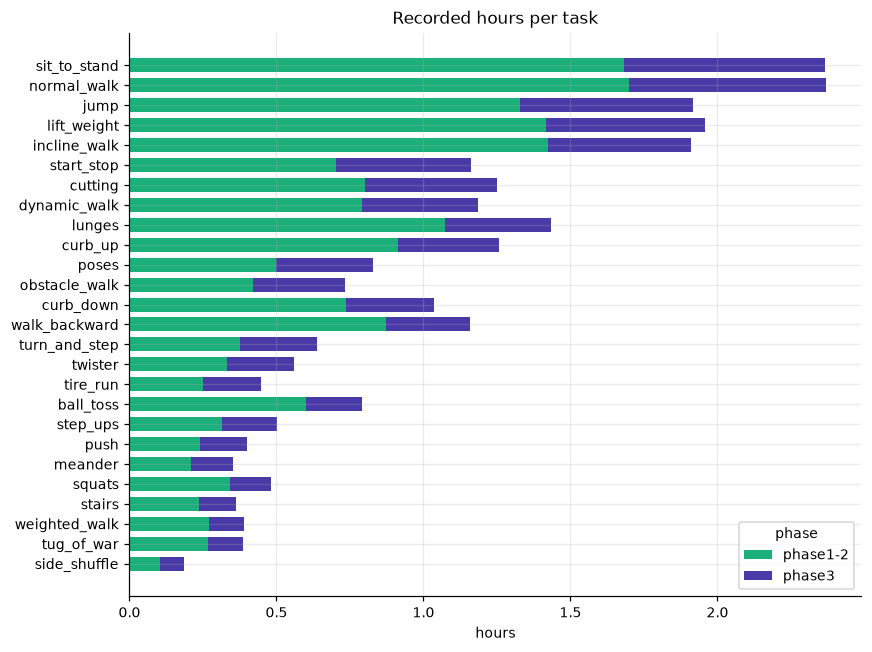

In [9]:
PAPER_GROUP = {'ball_toss': 'ball_toss', 'dynamic_walk': 'calisthenics / misc', 'tire_run': 'calisthenics', 'curb_up': 'curb',
               'curb_down': 'curb', 'cutting': 'cutting', 'incline_walk': 'incline / decline', 'jump': 'jump in place / across',
               'side_shuffle': 'jump across', 'lift_weight': 'lift_weight', 'lunges': 'lunge', 'meander': 'meander',
               'push': 'push_pull', 'normal_walk': 'walk / run / calisthenics', 'sit_to_stand': 'sit_stand', 'squats': 'squats',
               'stairs': 'stair ascent / descent', 'poses': 'stand', 'start_stop': 'start_stop', 'obstacle_walk': 'step_over',
               'step_ups': 'step_ups', 'tug_of_war': 'tug_of_war', 'turn_and_step': 'turn', 'twister': 'twister',
               'walk_backward': 'walk_backwards', 'weighted_walk': 'weighted_walk'}
PREVIOUS_MODE = {'normal_walk': 'LG', 'incline_walk': 'RA / RD', 'stairs': 'SA / SD', 'curb_up': 'SA (single step)',
                 'curb_down': 'SD (single step)', 'start_stop': 'TR', 'poses': 'ST'}
tasks = inv.pivot_table(index = 'task', columns = 'phase', values = 'seconds', aggfunc = 'sum').fillna(0) / 3600
tasks['recordings'] = inv.groupby('task').size()
tasks['paper group'] = tasks.index.map(PAPER_GROUP)
tasks['previous-dataset mode'] = tasks.index.map(PREVIOUS_MODE).fillna('none (new task)')
tasks = tasks.sort_values('phase3', ascending = False)
display(tasks.round(2))
fig, ax = plt.subplots(figsize = (8, 6))
left = np.zeros(len(tasks))
for phase in nt.PHASES:
    ax.barh(tasks.index, tasks[phase], left = left, color = PHASE_C[phase], label = phase, height = .7)
    left += tasks[phase].to_numpy()
ax.invert_yaxis(); ax.set_xlabel('hours'); ax.legend(title = 'phase'); ax.set_title('Recorded hours per task')
plt.tight_layout(); plt.show()

### 4.2 The activity flag
`Activity_Flag` is per leg and marks when the named task is happening. What the flag-off stretches *are* depends on
the task, and it decides whether they can be used: the table classifies them by whether the moment is still
valid (on the force plates) and, for treadmill tasks, whether the hip keeps moving (hip speed from the published
velocity channel, so only its ratio between in and out of task is used).

In [10]:
vel_abs = np.abs(core['hip_angle_l_velocity'].to_numpy())
f = pd.DataFrame({'task': core['task'], 'off': ~on, 'legs disagree': core['flag_l'].to_numpy() != core['flag_r'].to_numpy(),
                  'bio_ok': bio_ok, 'vel': vel_abs})
flag_table = f.groupby('task', observed = True).agg(off_share = ('off', 'mean'), legs_disagree = ('legs disagree', 'mean'))
flag_table['moment_valid_off'] = f[f.off].groupby('task', observed = True).bio_ok.mean()
flag_table['hip_speed_off'] = f[f.off].groupby('task', observed = True).vel.median()
flag_table['hip_speed_in'] = f[~f.off].groupby('task', observed = True).vel.median()
n_bouts = pd.Series({rec: len(sg.get_bouts(g.to_numpy() > 0, 2 * RATE)) for rec, g in core['flag_l'].groupby(rec_idx)})
flag_table['bouts of 2 s or more per recording'] = n_bouts.groupby(TASK_OF.reindex(n_bouts.index).to_numpy()).mean()


TREADMILL = {'normal_walk', 'incline_walk', 'dynamic_walk', 'walk_backward', 'weighted_walk', 'obstacle_walk'}


def get_off_kind(row):
    kind = 'none'
    if row.off_share > 0.02:
        kind = 'off the force plates (no moment)' if row.moment_valid_off < 0.5 else (
            'treadmill condition change' if row.name in TREADMILL and row.hip_speed_off >= 0.3 * row.hip_speed_in
            else 'rest between repetitions')
    return kind


flag_table['flag-off is'] = flag_table.apply(get_off_kind, axis = 1)
display(flag_table.sort_values(['flag-off is', 'off_share']).round(2))

,off_share,legs_disagree,moment_valid_off,hip_speed_off,hip_speed_in,bouts of 2 s or more per recording,flag-off is
task,,,,,,,
twister,0.00,0.00,NaN,NaN,3.260000,1.00,none
push,0.01,0.00,1.00,6.900000,7.430000,1.00,none
meander,0.01,0.00,0.00,6.100000,5.380000,1.04,none
poses,0.01,0.00,0.00,6.820000,1.790000,1.24,none
tug_of_war,0.01,0.00,0.00,7.530000,1.910000,1.00,none
stairs,0.08,0.18,0.00,26.150000,30.170000,0.87,off the force plates (no moment)
tire_run,0.39,0.10,0.01,6.820000,48.090000,10.92,off the force plates (no moment)
turn_and_step,0.45,0.15,0.02,21.879999,9.660000,10.56,off the force plates (no moment)
start_stop,0.53,0.14,0.00,13.270000,17.020000,19.08,off the force plates (no moment)


Three different things hide behind "flag off": **rest between repetitions** (hip nearly still, moments valid),
**treadmill condition changes** (still walking while speed or slope changes, moments valid; these are real
locomotion transitions with labels), and **walking off the force plates** (turnarounds, approach and exit on
stairs, curbs, cutting, start-stop: no moment). The flag alone is not a transition label; flag plus task is.
Left and right flags disagree on stairs and curbs, where one foot is on the instrumented step before the other,
so each leg's target should be masked by its own flag.

### 4.3 Recovering the conditions the Complete names drop
Speed, slope and direction are encoded only in the Parsed variant's names. Two of them can be recovered: stair
recordings alternate up and down by their last index (readme), and each in-task bout's mean leg joint power
(hip + knee + ankle, both legs) separates uphill from downhill.

stairs: readme index parity vs sign of leg power agree on 100.0% of 327 passes
incline bouts by recovered direction: {'up': 80, 'down': 70}


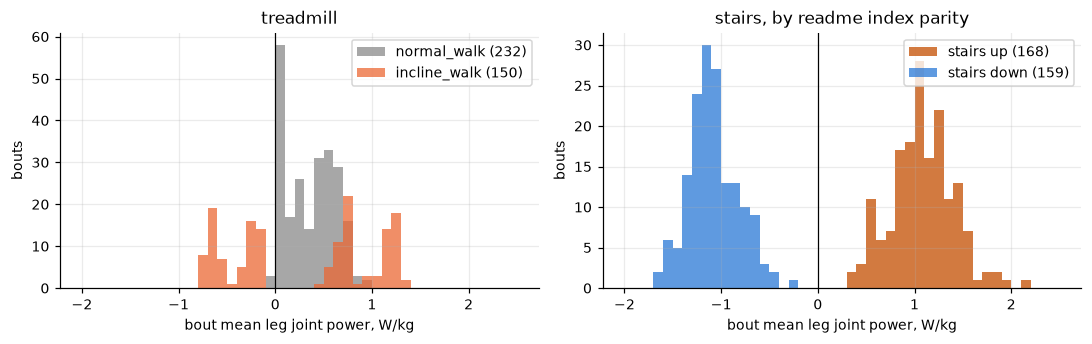

In [11]:
def get_bout_metrics(recs):
    """Per in-task bout (left flag, at least 2 s): mean leg power and the gait metrics used in section 7."""
    cols = ['flag_l', 'hip_angle_l', 'thigh_imu_l_gyro_z', 'bio_l', 'limb_power_l', 'limb_power_r']
    d = nt.load_samples(cols, recs = recs)
    rows = []
    for rec, g in d.groupby('rec'):
        for s, e in sg.get_bouts(g.flag_l.to_numpy() > 0, 2 * RATE):
            x = g.iloc[s:e]
            m = -x.bio_l.to_numpy()                                   # extension positive
            rows.append(dict(rec = rec, seconds = (e - s) / RATE,
                             limb_power = float(np.nanmean(x[['limb_power_l', 'limb_power_r']].to_numpy())),
                             stride_s = sg.get_stride_period(x.hip_angle_l.to_numpy()) if e - s >= 6 * RATE else np.nan,
                             hip_rom = float(np.nanpercentile(x.hip_angle_l, 95) - np.nanpercentile(x.hip_angle_l, 5)),
                             gyro_sag_p95 = float(np.nanpercentile(np.abs(x.thigh_imu_l_gyro_z), 95)),
                             moment_ext = float(np.nanpercentile(m, 95)) if np.isfinite(m).any() else np.nan,
                             moment_flex = float(np.nanpercentile(m, 5)) if np.isfinite(m).any() else np.nan,
                             moment_valid = float(np.isfinite(m).mean())))
    return pd.DataFrame(rows).merge(inv[['rec', 'phase', 'subject', 'recording', 'task', 'stair_dir']], on = 'rec')


bouts = get_bout_metrics(inv.loc[inv.task.isin(['normal_walk', 'incline_walk', 'stairs']), 'rec'])
st = bouts[bouts.task == 'stairs']
print(f"stairs: readme index parity vs sign of leg power agree on {np.mean((st.limb_power > 0) == (st.stair_dir == 'up')):.1%} of {len(st)} passes")
iw = bouts[bouts.task == 'incline_walk'].copy()
iw['direction'] = np.where(iw.limb_power > 0.1, 'up', np.where(iw.limb_power < -0.1, 'down', 'unclear'))
print('incline bouts by recovered direction:', iw.direction.value_counts().to_dict())
bouts.loc[iw.index, 'direction'] = iw.direction
bouts.loc[st.index, 'direction'] = st.stair_dir
fig, axes = plt.subplots(1, 2, figsize = (10, 3.2), sharey = False)
bins = np.linspace(-2, 2.5, 46)
for ax, (title, parts) in zip(axes, [('treadmill', [('normal_walk', None, '#8a8a8a'), ('incline_walk', None, NATURE_C)]),
                                     ('stairs, by readme index parity', [('stairs', 'up', '#c44e00'), ('stairs', 'down', '#2a78d6')])]):
    for task, d_, color in parts:
        sel = bouts[(bouts.task == task) & ((bouts.direction == d_) if d_ else True)]
        ax.hist(sel.limb_power, bins = bins, color = color, alpha = .75, label = f'{task}{" " + d_ if d_ else ""} ({len(sel)})')
    ax.axvline(0, color = 'k', lw = .8); ax.set_xlabel('bout mean leg joint power, W/kg'); ax.set_ylabel('bouts'); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

Stair direction from the readme rule and from joint power agree on every pass, and incline bouts fall into two
clean clusters (nothing between −0.1 and +0.3 W/kg), so **up / down is recoverable for both ramps and stairs**.
The incline histogram also shows four clusters rather than two, which suggests slope magnitude (5° vs 10°) is
recoverable the same way; that is not verified here. Treadmill speed (0.6–2.5 m/s) is not recovered; if it
matters, the Parsed variant's names carry it.

## 5. The hip moment

### 5.1 Coverage
Within the task the moment is valid almost everywhere; out of task it depends on the flag-off kind (4.2). The
previous dataset's moments exist only on the force plates: on its stairs about 40% of samples.

In [12]:
cov = pd.DataFrame({'task': core['task'], 'on': on, 'bio_ok': bio_ok}).groupby(['task', 'on'], observed = True).bio_ok.mean().unstack()
cov.columns = ['valid out of task', 'valid in task']
cov['valid overall'] = pd.Series(bio_ok).groupby(core['task'].to_numpy()).mean()
leg = pd.DataFrame({'l': np.isfinite(core['bio_l'].to_numpy()), 'r': np.isfinite(core['bio_r'].to_numpy())}).groupby(rec_idx).mean()
dead = inv.set_index('rec').loc[leg.index[(leg.l < .05) | (leg.r < .05)], ['phase', 'subject', 'recording']]
sm = nt.load_samples(['moment_l'], name = 'scirob_samples').merge(sinv[['rec', 'mode']], on = 'rec')
prev_cov = sm.assign(ok = sm.moment_l.notna()).groupby('mode').ok.mean()
display(cov.sort_values('valid overall').round(3))
print('previous dataset, moment valid share by mode:', prev_cov.round(2).to_dict())
print(f'{len(dead)} recordings have a leg with <5% valid moment (the treadmill load-cell failure the readme documents):')
display(dead)

,valid out of task,valid in task,valid overall
task,,,
cutting,0.003,0.983,0.198
curb_up,0.002,1.000,0.199
curb_down,0.000,1.000,0.218
start_stop,0.001,0.997,0.473
turn_and_step,0.018,0.998,0.554
tire_run,0.007,1.000,0.610
stairs,0.003,1.000,0.922
incline_walk,0.909,0.972,0.937
side_shuffle,0.944,0.953,0.947


previous dataset, moment valid share by mode: {'LG': 0.83, 'RA': 0.89, 'RD': 0.87, 'SA': 0.36, 'SD': 0.34, 'ST': 0.94, 'TR': 0.91}
15 recordings have a leg with <5% valid moment (the treadmill load-cell failure the readme documents):


,phase,subject,recording
7,phase1-2,BT01,dynamic_walk_1
8,phase1-2,BT01,dynamic_walk_2
30,phase1-2,BT01,obstacle_walk_1
67,phase1-2,BT01,walk_backward_1
68,phase1-2,BT01,weighted_walk_1
101,phase1-2,BT02,obstacle_walk_1
174,phase1-2,BT03,obstacle_walk_1
655,phase1-2,BT12,dynamic_walk_1_1
656,phase1-2,BT12,dynamic_walk_1_2
676,phase1-2,BT12,normal_walk_1_1


### 5.2 Filtering
The filtered moments come from a 6 Hz, 5th-order Butterworth. Lag between the raw and filtered net moment:

In [13]:
mm = nt.load_samples(['net_raw_l', 'net_l'], recs = WALK.rec)
lags = [sg.get_lag_corr(g.net_raw_l.to_numpy(), g.net_l.to_numpy(), 10)[0] for _, g in mm.groupby('rec')]
print('raw -> filtered lag (samples) over', len(lags), 'walking recordings:', pd.Series(lags).value_counts().to_dict())

raw -> filtered lag (samples) over 126 walking recordings: {0: 126}


Zero lag: the filter is **zero-phase (non-causal)**, as the readme's file notes say, and as in the previous dataset.
Fine as a training target, but the target at time *t* already contains information from up to roughly 100 ms
after *t*. A forecaster's horizon should be judged against that smoothing, and a causal estimator cannot match
the target's phase exactly.

### 5.3 What the exo contributes: net versus biological moment
Net minus biological moment is the exo's interaction torque divided by body mass. Whether a recording was
powered is read from the **measured** torque (desired torque is computed even with the exo off).

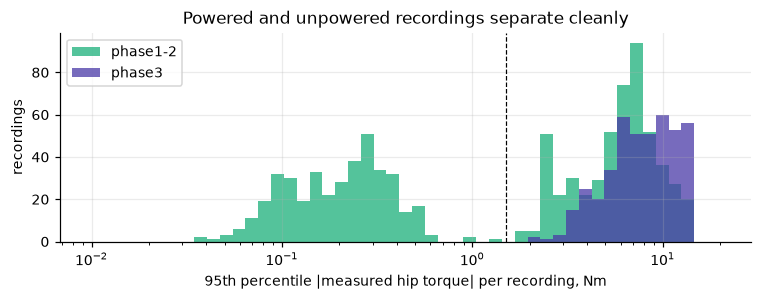

recordings  p95 |net - bio|  p95 |bio|  assistance share
phase    powered                                                          
phase1-2 False         409.0            0.007      0.909             0.008
         True          519.0            0.103      0.865             0.119
phase3   True          430.0            0.137      0.831             0.165

corr(net - bio, interaction torque) over 126 walking recordings: median -1.0000


In [14]:
x = pd.DataFrame({'rec': rec_idx, 'tq': np.abs(core['tq_meas_l'].to_numpy()), 'd': core['net_l'].to_numpy() - core['bio_l'].to_numpy(),
                  'bio': core['bio_l'].to_numpy()})
rec_tq = x.groupby('rec').tq.quantile(.95)
inv['tq_p95'] = inv.rec.map(rec_tq)
inv['powered'] = inv.tq_p95 > 1.5
fig, ax = plt.subplots(figsize = (7, 2.8))
bins = np.logspace(-2, 1.3, 50)
for phase in nt.PHASES:
    ax.hist(inv.loc[inv.phase == phase, 'tq_p95'], bins = bins, color = PHASE_C[phase], alpha = .75, label = phase)
ax.axvline(1.5, color = 'k', lw = .8, ls = '--'); ax.set_xscale('log'); ax.set_xlabel('95th percentile |measured hip torque| per recording, Nm')
ax.set_ylabel('recordings'); ax.legend(); ax.set_title('Powered and unpowered recordings separate cleanly'); plt.tight_layout(); plt.show()
x['powered'] = inv.set_index('rec').powered.to_numpy()[rec_idx]
x['phase'] = core['phase']
assist = x.groupby(['phase', 'powered'], observed = True).apply(lambda g: pd.Series({
    'recordings': g.rec.nunique(), 'p95 |net - bio|': np.nanpercentile(np.abs(g.d), 95), 'p95 |bio|': np.nanpercentile(np.abs(g.bio), 95)}))
assist['assistance share'] = assist['p95 |net - bio|'] / assist['p95 |bio|']
display(assist.round(3))
ti = nt.load_samples(['net_l', 'bio_l', 'tq_int_l'], recs = WALK.rec)
r_int = [sg.get_corr(g.tq_int_l, g.net_l - g.bio_l) for _, g in ti.groupby('rec')]
print(f'corr(net - bio, interaction torque) over {len(r_int)} walking recordings: median {np.nanmedian(r_int):.4f}')
del x, ti

The "with and without exo" contrast only exists where the exo was powered: about **12% of the peak biological
moment** in powered Phase 1–2 recordings and **17%** in Phase 3, under 1% when unpowered (so in unpowered
Phase 1 recordings the two targets are the same). Net − bio is exactly the interaction torque over mass
(r = −1, the sign being the exo's extension-positive convention), so either target can be rebuilt from the other.

### 5.4 How large the moment gets, by task

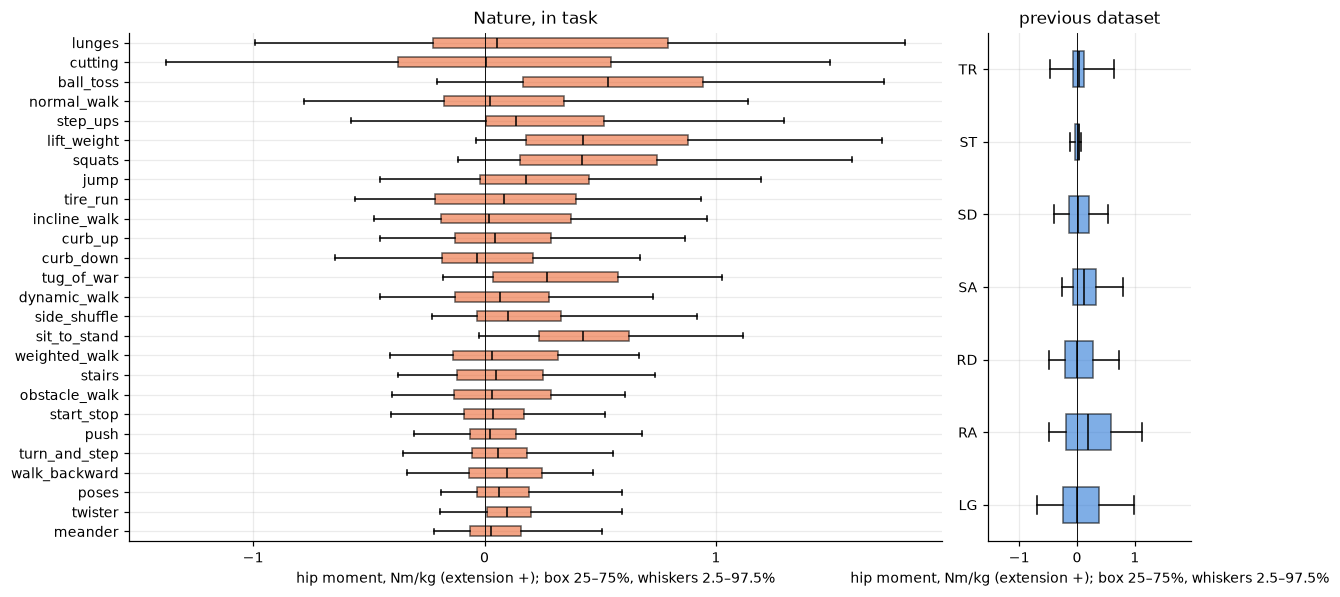

In [15]:
rng = np.random.default_rng(0)
ext = pd.DataFrame({'task': core['task'], 'm': -core['bio_l'].to_numpy()})[on & bio_ok]
ext = ext.groupby('task', observed = True).sample(n = 20000, replace = True, random_state = 0)
order = ext.groupby('task', observed = True).m.apply(lambda s: s.quantile(.95) - s.quantile(.05)).sort_values().index
prev = sm.dropna().groupby('mode').sample(n = 20000, replace = True, random_state = 0)
fig, axes = plt.subplots(1, 2, figsize = (11, 5.5), gridspec_kw = {'width_ratios': [4, 1]}, sharex = True)
axes[0].boxplot([ext.loc[ext.task == t, 'm'] for t in order], orientation = 'horizontal', whis = (2.5, 97.5), showfliers = False,
                patch_artist = True, boxprops = dict(facecolor = NATURE_C, alpha = .6), medianprops = dict(color = 'k'))
axes[0].set_yticks(range(1, len(order) + 1), order); axes[0].set_title('Nature, in task')
modes = list(nt.SCIROB_MODES)
axes[1].boxplot([prev.loc[prev['mode'] == m_, 'moment_l'] for m_ in modes], orientation = 'horizontal', whis = (2.5, 97.5), showfliers = False,
                patch_artist = True, boxprops = dict(facecolor = SCIROB_C, alpha = .6), medianprops = dict(color = 'k'))
axes[1].set_yticks(range(1, len(modes) + 1), modes); axes[1].set_title('previous dataset'); axes[1].set_xticks([-1, 0, 1])
for ax in axes:
    ax.axvline(0, color = 'k', lw = .6); ax.set_xlabel('hip moment, Nm/kg (extension +); box 25–75%, whiskers 2.5–97.5%')
plt.tight_layout(); plt.show()

Walking spans about −0.8 to +1.1 Nm/kg in both datasets. Lunges and cutting span about half as much again, and
lifting, squats, sit-to-stand, ball toss and tug of war hold large **sustained extension moments** (medians
0.3–0.5 Nm/kg) that no previous-dataset mode has. A model trained on this set covers a wider and differently shaped
output range than one trained on the previous modes, which matters for output scaling and for what "out of
distribution" means downstream.

### 5.5 The benchmark: the paper's own estimator
`torque_estimated` is the deployed estimator's output (time-realigned for its delay, exo convention). It used
more sensors than this project will (hip *and knee* encoders, thigh, shank and foot IMUs), so it is a ceiling to
compare against rather than a like-for-like baseline. The previous dataset's `trq_est` is scored the same way.

,samples,rmse,r2
phase,,,
phase1-2,1533755.0,0.207,0.691
phase3,3011992.0,0.165,0.823


,Nature phase 3 (validation),previous dataset (study pool)
"RMSE mean, Nm/kg",0.164,0.155
RMSE sd,0.019,0.030
R² mean,0.821,0.847
R² sd,0.031,0.062


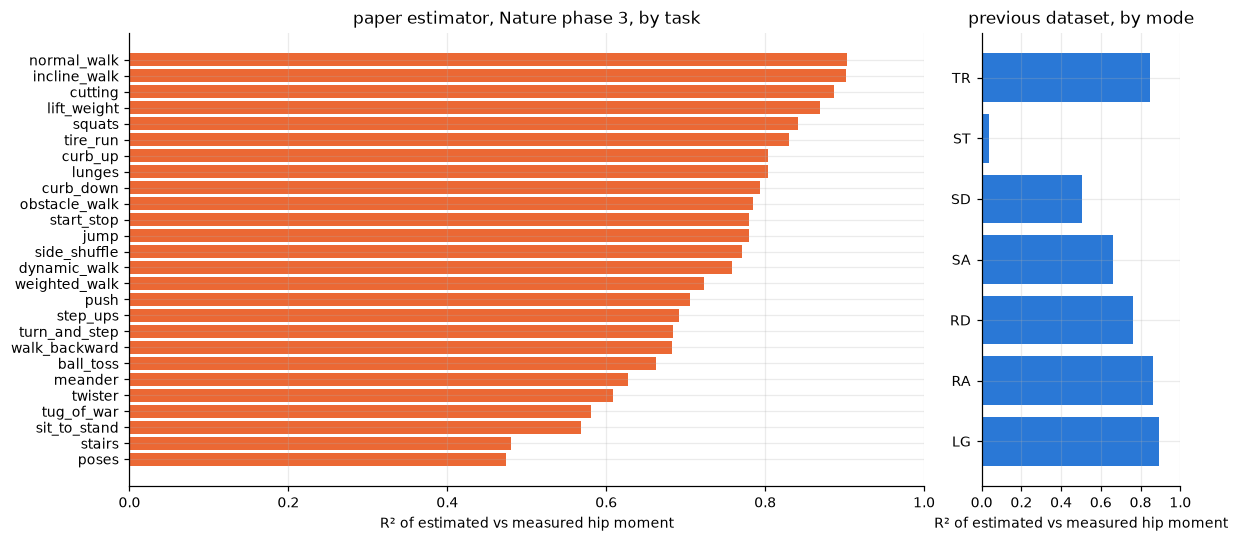

In [16]:
def score(y, p):
    ok = np.isfinite(y) & np.isfinite(p)
    y, p = y[ok], p[ok]
    return pd.Series(dict(samples = len(y), rmse = np.sqrt(np.mean((p - y) ** 2)),
                          r2 = 1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2)))


e = pd.DataFrame({'phase': core['phase'], 'task': core['task'], 'subject': inv.set_index('rec').subject.to_numpy()[rec_idx],
                  'y': -core['bio_l'].to_numpy(), 'p': core['tq_est_l'].to_numpy()})[on & np.isfinite(core['tq_est_l'].to_numpy())]
by_phase = e.groupby('phase', observed = True).apply(lambda g: score(g.y.to_numpy(), g.p.to_numpy()))
per_person = e[e.phase == 'phase3'].groupby('subject').apply(lambda g: score(g.y.to_numpy(), g.p.to_numpy()))
by_task = e[e.phase == 'phase3'].groupby('task', observed = True).apply(lambda g: score(g.y.to_numpy(), g.p.to_numpy())).sort_values('r2')
pe = nt.load_samples(['moment_l', 'trq_est_l'], name = 'scirob_samples').merge(sinv[['rec', 'subject', 'mode']], on = 'rec')
prev_mode = pe.groupby('mode').apply(lambda g: score(g.moment_l.to_numpy(), g.trq_est_l.to_numpy()))
prev_person = pe.groupby('subject').apply(lambda g: score(g.moment_l.to_numpy(), g.trq_est_l.to_numpy()))
display(by_phase.round(3))
bench = pd.DataFrame({'Nature phase 3 (validation)': [per_person.rmse.mean(), per_person.rmse.std(), per_person.r2.mean(), per_person.r2.std()],
                      'previous dataset (study pool)': [prev_person.rmse.mean(), prev_person.rmse.std(), prev_person.r2.mean(), prev_person.r2.std()]},
                     index = ['RMSE mean, Nm/kg', 'RMSE sd', 'R² mean', 'R² sd'])
display(bench.round(3))
fig, axes = plt.subplots(1, 2, figsize = (11, 5), gridspec_kw = {'width_ratios': [4, 1]}, sharex = True)
axes[0].barh(by_task.index, by_task.r2, color = NATURE_C); axes[0].set_title('paper estimator, Nature phase 3, by task')
axes[1].barh(prev_mode.index, prev_mode.r2, color = SCIROB_C); axes[1].set_title('previous dataset, by mode')
for ax in axes:
    ax.set_xlabel('R² of estimated vs measured hip moment'); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

Per participant, the deployed estimator reaches about **0.16 Nm/kg RMSE and R² 0.82** on the Phase 3 participants
(the previous dataset's estimator: about 0.16 and 0.85 on its own study pool, close to its paper's 0.142 and 0.84).
Both are best on cyclic walking (R² ≈ 0.9) and worst where the moment is small or quasi-static: standing poses,
stairs, sit-to-stand, tug of war. Those are the tasks where a fallback estimator is weakest, and the natural
candidates for "OOD-dangerous" in the awareness framework.

## 6. Forecasting the moment, and what the sensors carry

### 6.1 How far the moment moves within a horizon
A forecaster must predict the change of the moment over its horizon on top of estimating it now. The size of that
change, as RMSE of *m(t + h) − m(t)* divided by the moment's spread within the task, is a training-free measure of
how hard each horizon is (values above 1 mean the moment changes by more than its own standard deviation):

,sd,50 ms,100 ms,200 ms,500 ms
task,,,,,
tug_of_war,0.35,0.13,0.23,0.35,0.50
lunges,0.73,0.15,0.29,0.50,0.95
poses,0.20,0.18,0.34,0.55,0.83
squats,0.44,0.16,0.30,0.56,1.05
lift_weight,0.49,0.17,0.33,0.60,1.14
meander,0.19,0.22,0.41,0.70,1.17
twister,0.20,0.28,0.51,0.81,1.12
sit_to_stand,0.29,0.29,0.53,0.85,1.20
step_ups,0.47,0.32,0.59,0.98,1.15


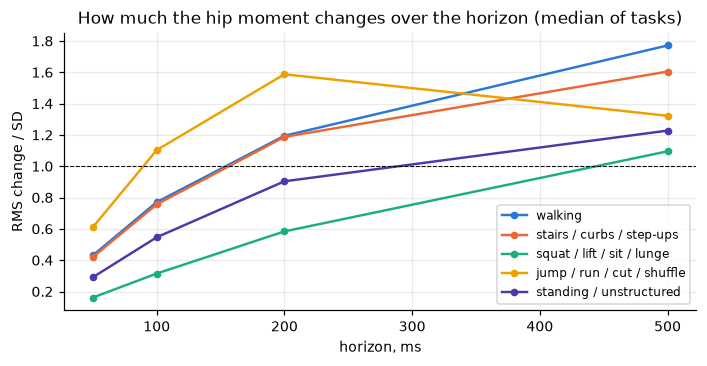

In [17]:
H = {'50 ms': 10, '100 ms': 20, '200 ms': 40, '500 ms': 100}
m_on = np.where(on, core['bio_l'].to_numpy(), np.nan)
rows = []
for task, idx in pd.Series(np.arange(len(core))).groupby(core['task'].to_numpy()):
    i = idx.to_numpy()
    m, r = m_on[i], rec_idx[i]
    row = dict(task = task, sd = np.nanstd(m))
    for name, h in H.items():
        same = r[h:] == r[:-h]
        row[name] = np.sqrt(np.nanmean(((m[h:] - m[:-h])[same]) ** 2)) / row['sd']
    rows.append(row)
persist = pd.DataFrame(rows).set_index('task').sort_values('200 ms')
display(persist.round(2))
GROUPS = {'walking': ['normal_walk', 'incline_walk', 'walk_backward', 'weighted_walk', 'dynamic_walk', 'obstacle_walk'],
          'stairs / curbs / step-ups': ['stairs', 'curb_up', 'curb_down', 'step_ups'],
          'squat / lift / sit / lunge': ['squats', 'lift_weight', 'sit_to_stand', 'lunges'],
          'jump / run / cut / shuffle': ['jump', 'tire_run', 'cutting', 'side_shuffle'],
          'standing / unstructured': ['poses', 'tug_of_war', 'push', 'twister', 'meander', 'start_stop', 'turn_and_step', 'ball_toss']}
fig, ax = plt.subplots(figsize = (6.5, 3.4))
hz = [h / RATE * 1000 for h in H.values()]
for (name, ts), color in zip(GROUPS.items(), ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#4a3aa7']):
    ax.plot(hz, persist.loc[ts, list(H)].median(), marker = 'o', ms = 4, lw = 1.6, color = color, label = name)
ax.axhline(1, color = 'k', lw = .7, ls = '--'); ax.set_xlabel('horizon, ms'); ax.set_ylabel('RMS change / SD')
ax.set_title('How much the hip moment changes over the horizon (median of tasks)'); ax.legend(fontsize = 8); plt.tight_layout(); plt.show()

In 50 ms the moment moves by about half its spread in locomotion; by 200 ms it moves by more than its spread in
every cyclic task, and only the slow, quasi-static tasks stay under 1. Practical horizons for compensating
actuation and estimator delay (tens of ms) are a modest step beyond estimation; 200 ms and beyond is a
genuinely different, harder prediction problem whose difficulty differs sharply between task families. (The
jump family falls again at 500 ms because those moments repeat at about that period.)

### 6.2 Which of the 16 channels track the moment
Best |r| between each left-side channel and the left hip moment within ±250 ms, median over up to 60 recordings
per task family (single-channel and linear, so a floor on what a model can extract, not a ceiling):

In [18]:
rng = np.random.default_rng(0)
LEFT = nt.NATURE_16[:8]
rows = []
for gname, ts in GROUPS.items():
    recs = inv.loc[inv.task.isin(ts), 'rec'].to_numpy()
    recs = rng.choice(recs, min(60, len(recs)), replace = False)
    sub = core.loc[np.isin(rec_idx, recs), ['rec', 'flag_l', 'bio_l', *LEFT]]
    for ch in LEFT:
        res = [sg.get_lag_corr(np.where(g.flag_l > 0, g[ch], np.nan), np.where(g.flag_l > 0, g.bio_l, np.nan), 50) for _, g in sub.groupby('rec')]
        rows.append(dict(group = gname, channel = ch, best_abs_r = np.nanmedian([abs(r[1]) for r in res])))
sens = pd.DataFrame(rows).pivot(index = 'channel', columns = 'group', values = 'best_abs_r').loc[LEFT, list(GROUPS)]
display(sens.round(2))

group,walking,stairs / curbs / step-ups,squat / lift / sit / lunge,jump / run / cut / shuffle,standing / unstructured
channel,,,,,
thigh_imu_l_accel_x,0.50,0.51,0.64,0.45,0.45
thigh_imu_l_accel_y,0.32,0.40,0.38,0.38,0.18
thigh_imu_l_accel_z,0.50,0.48,0.60,0.26,0.39
thigh_imu_l_gyro_x,0.53,0.59,0.24,0.30,0.28
thigh_imu_l_gyro_y,0.39,0.52,0.25,0.22,0.20
thigh_imu_l_gyro_z,0.74,0.70,0.37,0.59,0.26
hip_angle_l,0.82,0.77,0.71,0.63,0.56
hip_angle_l_velocity,0.71,0.67,0.42,0.60,0.31


The same table aggregated: the three channels that track the moment best in each task family, named by the
anatomical axis each IMU axis points along (3.4: up = `y`, mediolateral = `z`, anterior = `x`).

In [19]:
AXIS_NAME = {'hip_angle_l': 'hip angle', 'hip_angle_l_velocity': 'hip velocity',
             'thigh_imu_l_gyro_z': 'sagittal gyro (z)', 'thigh_imu_l_gyro_x': 'frontal-plane gyro (x)', 'thigh_imu_l_gyro_y': 'long-axis gyro (y)',
             'thigh_imu_l_accel_x': 'anterior accel (x)', 'thigh_imu_l_accel_y': 'long-axis accel (y)', 'thigh_imu_l_accel_z': 'mediolateral accel (z)'}
top = pd.DataFrame({g: [f'{AXIS_NAME[c]}  {sens.loc[c, g]:.2f}' for c in sens[g].sort_values(ascending = False).index[:3]] for g in sens},
                   index = ['1st', '2nd', '3rd']).T
top['weakest'] = [f'{AXIS_NAME[sens[g].idxmin()]}  {sens[g].min():.2f}' for g in sens]
top['moment is driven by'] = ['motion', 'motion', 'posture (thigh inclination)', 'motion', 'posture, weakly']
display(top)

,1st,2nd,3rd,weakest,moment is driven by
walking,hip angle 0.82,sagittal gyro (z) 0.74,hip velocity 0.71,long-axis accel (y) 0.32,motion
stairs / curbs / step-ups,hip angle 0.77,sagittal gyro (z) 0.70,hip velocity 0.67,long-axis accel (y) 0.40,motion
squat / lift / sit / lunge,hip angle 0.71,anterior accel (x) 0.64,mediolateral accel (z) 0.60,frontal-plane gyro (x) 0.24,posture (thigh inclination)
jump / run / cut / shuffle,hip angle 0.63,hip velocity 0.60,sagittal gyro (z) 0.59,long-axis gyro (y) 0.22,motion
standing / unstructured,hip angle 0.56,anterior accel (x) 0.45,mediolateral accel (z) 0.39,long-axis accel (y) 0.18,"posture, weakly"


The encoder angle is the best single channel in every family. In locomotion (walking, stairs, jumping and running)
the motion channels follow it: the sagittal gyro and hip velocity, |r| 0.6–0.8. In squats, lifting, sit-to-stand
and lunges the accelerometers take second and third place instead: there the moment follows how far the thigh is
inclined, which the accelerometers read from gravity, rather than how fast it moves. Every channel is weak on standing and
unstructured tasks, where the moment is set by load and posture rather than by motion. That matches where the
paper's richer-sensor estimator is weakest, and it is where hip-encoder-plus-thigh-IMU alone will struggle most.

## 7. Side by side with the previous dataset

### 7.1 Size and labels
Windows are counted the way the existing pipeline cuts them: 1 s (200 samples) at stride 10, all 16 sensor
channels valid; "labelled" additionally needs a valid hip moment (either leg) at the window's last sample.

In [20]:
def count_windows(valid, labelled, recs, win = 200, stride = 10):
    """(windows, labelled windows) over recordings, a window = `win` consecutive valid samples, ends every `stride`."""
    total, with_label = 0, 0
    starts = np.r_[0, np.flatnonzero(np.diff(recs)) + 1, len(recs)]
    for a, b in zip(starts[:-1], starts[1:]):
        bad = np.r_[0, np.cumsum(~valid[a:b])]
        ends = np.arange(win - 1, b - a, stride)
        ok = (bad[ends + 1] - bad[ends + 1 - win]) == 0
        total += int(ok.sum())
        with_label += int((ok & labelled[a:b][ends]).sum())
    return total, with_label


nat_win = count_windows(sens_ok, bio_ok | np.isfinite(core['bio_r'].to_numpy()), rec_idx)
ps = nt.load_samples([*nt.SCIROB_16, 'moment_l', 'moment_r'], name = 'scirob_samples')
prev_ok = np.isfinite(ps[nt.SCIROB_16].to_numpy()).all(1)
prev_win = count_windows(prev_ok, np.isfinite(ps[['moment_l', 'moment_r']].to_numpy()).any(1), ps.rec.to_numpy())
side = pd.DataFrame({
    'previous (Science Robotics, study pool)': [sinv.subject.nunique(), '1', f"{sinv.assign(s = sinv.rec.map(ps.groupby('rec').size())).s.sum() / RATE / 3600:.1f}",
                                                len(sinv), '7 modes (LG RA RD SA SD ST TR)', f'{prev_win[0]:,}', f'{prev_win[1]:,}',
                                                f"{np.isfinite(ps[['moment_l']].to_numpy()).mean():.0%}", 'net or biological: not stated', 'every trial (unified controller)',
                                                'in trial names', 'yes (gp.csv)', 'custom hip exo'],
    'Nature 2024 (Complete)': [inv.subject.nunique(), '1 or 2 (3 people twice)', f'{inv.seconds.sum() / 3600:.1f}', len(inv), '26 tasks',
                               f'{nat_win[0]:,}', f'{nat_win[1]:,}', f'{bio_ok.mean():.0%} (in task {bio_ok[on].mean():.1%})',
                               'net and biological', 'Phase 1 mostly off; Phases 2-3 on', 'stairs, incline direction recoverable; speed and slope not',
                               'no (derivable from GRF and insoles)', 'hip-and-knee exo']},
    index = ['participants', 'sessions per person', 'hours', 'recordings / trials', 'tasks', '1 s windows (stride 10)',
             'windows with a hip-moment label', 'samples with a hip moment', 'moment type', 'exo assistance', 'condition labels',
             'gait-phase labels', 'hardware'])
display(side)

,"previous (Science Robotics, study pool)",Nature 2024 (Complete)
participants,20,22
sessions per person,1,1 or 2 (3 people twice)
hours,6.3,26.1
recordings / trials,1505,1358
tasks,7 modes (LG RA RD SA SD ST TR),26 tasks
1 s windows (stride 10),"422,009","1,840,620"
windows with a hip-moment label,"352,091","1,574,432"
samples with a hip moment,73%,84% (in task 99.4%)
moment type,net or biological: not stated,net and biological
exo assistance,every trial (unified controller),Phase 1 mostly off; Phases 2-3 on


### 7.2 Matched tasks
Where the task sets overlap, do the movements look alike? Nature bouts (in task, at least 2 s) against previous
trials: level treadmill walking (all speeds both sides), ramps up and down (Nature ±5° and ±10° at 1.2 m/s;
previous ±5° to ±15° at 0.75–1.25 m/s), and stair ascent and descent. Hip angles in degrees; the sagittal gyro is
`gyro_z` in Nature and `gyro_y` in the previous dataset (3.4); stride period only from treadmill bouts of at least 6 s.

Nature  previous  n_nature  n_previous
task          metric                                                                   
level walking hip range of motion, deg            45.65     49.90       232         207
              sagittal thigh gyro p95, deg/s     245.43    224.95       232         207
              stride period, s                     1.06      1.04       231         207
              hip moment p95 (extension), Nm/kg    0.83      0.75       232         207
              hip moment p5 (flexion), Nm/kg      -0.52     -0.51       232         207
ramp ascent   hip range of motion, deg            55.19     63.42        80         120
              sagittal thigh gyro p95, deg/s     218.00    199.06        80         120
              stride period, s                     1.10      1.14        80         120
              hip moment p95 (extension), Nm/kg    0.89      0.98        80         120
              hip moment p5 (flexion), Nm/kg      -0.35     -0.33        80         120
ramp descent  hip range of motion, deg            37.82     30.23        70         119
              sagittal thigh gyro p95, deg/s     192.35    146.89        70         119
              stride period, s                     1.02      1.01        70         119
              hip moment p95 (extension), Nm/kg    0.56      0.53        66         119
              hip moment p5 (flexion), Nm/kg      -0.40     -0.38        66         119
stair ascent  hip range of motion, deg            53.69     65.27       168         513
              sagittal thigh gyro p95, deg/s     182.78    189.68       168         513
              hip moment p95 (extension), Nm/kg    0.58      0.63       168         510
              hip moment p5 (flexion), Nm/kg      -0.23     -0.22       168         510
stair descent hip range of motion, deg            28.66     42.33       159         517
              sagittal thigh gyro p95, deg/s     126.01    154.82       159         517
              hip moment p95 (extension), Nm/kg    0.42      0.43       159         513
              hip moment p5 (flexion), Nm/kg      -0.30     -0.28       159         513

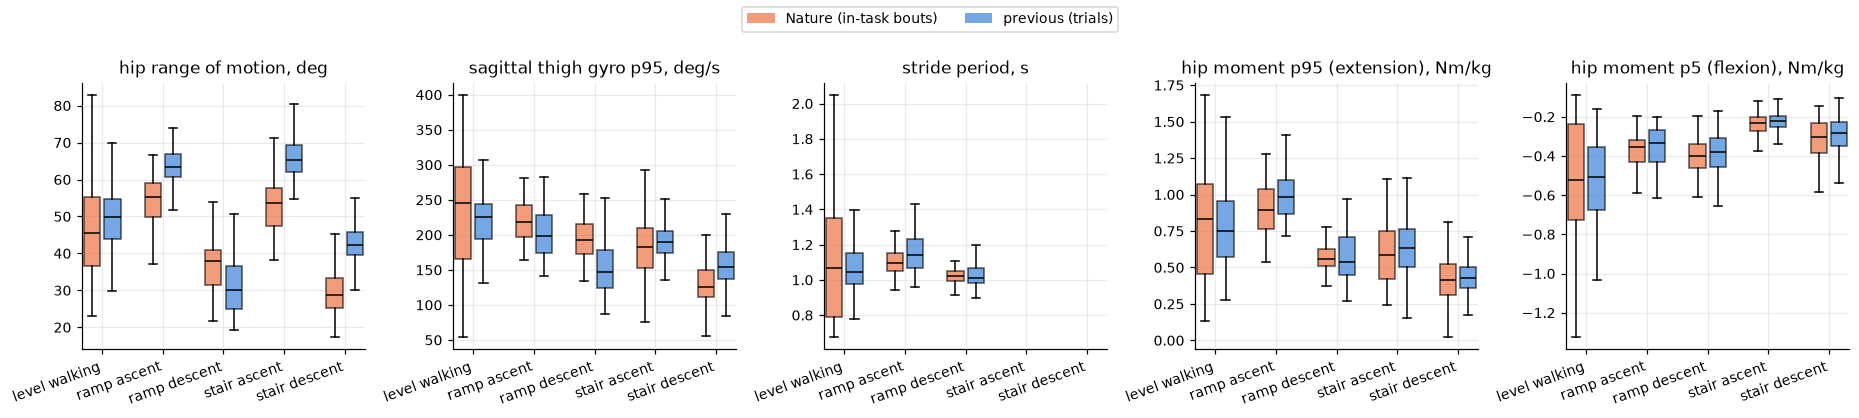

In [21]:
def get_trial_metrics(recs):
    d = nt.load_samples(['enc_angle_l', 'thigh_gyro_y_l', 'moment_l'], recs = recs, name = 'scirob_samples')
    rows = []
    for rec, g in d.groupby('rec'):
        ang, m = np.degrees(g.enc_angle_l.to_numpy()), g.moment_l.to_numpy()
        rows.append(dict(rec = rec, stride_s = sg.get_stride_period(ang) if len(g) >= 6 * RATE else np.nan,
                         hip_rom = np.nanpercentile(ang, 95) - np.nanpercentile(ang, 5),
                         gyro_sag_p95 = np.nanpercentile(np.abs(np.degrees(g.thigh_gyro_y_l)), 95),
                         moment_ext = np.nanpercentile(m, 95) if np.isfinite(m).any() else np.nan,
                         moment_flex = np.nanpercentile(m, 5) if np.isfinite(m).any() else np.nan,
                         moment_valid = np.isfinite(m).mean()))
    return pd.DataFrame(rows).merge(sinv[['rec', 'subject', 'mode', 'condition', 'speed']], on = 'rec')


trials = get_trial_metrics(sinv.loc[sinv['mode'].isin(['LG', 'RA', 'RD', 'SA', 'SD']), 'rec'])
trials = trials[(trials['mode'].isin(['SA', 'SD'])) | (trials.speed > 0)]
MATCH = {'level walking': (('normal_walk', None), 'LG'), 'ramp ascent': (('incline_walk', 'up'), 'RA'),
         'ramp descent': (('incline_walk', 'down'), 'RD'), 'stair ascent': (('stairs', 'up'), 'SA'), 'stair descent': (('stairs', 'down'), 'SD')}
METRICS = {'hip_rom': 'hip range of motion, deg', 'gyro_sag_p95': 'sagittal thigh gyro p95, deg/s', 'stride_s': 'stride period, s',
           'moment_ext': 'hip moment p95 (extension), Nm/kg', 'moment_flex': 'hip moment p5 (flexion), Nm/kg'}
pairs, rows = {}, []
for name, ((task, direction), mode) in MATCH.items():
    nb = bouts[(bouts.task == task) & ((bouts.direction == direction) if direction else True)].copy()
    pt = trials[trials['mode'] == mode].copy()
    if task == 'stairs':                      # single passes are too short for a stride period
        nb['stride_s'], pt['stride_s'] = np.nan, np.nan
    pairs[name] = (nb, pt)
    for k in METRICS:
        rows.append(dict(task = name, metric = METRICS[k], Nature = nb[k].median(), previous = pt[k].median(), n_nature = nb[k].notna().sum(), n_previous = pt[k].notna().sum()))
display(pd.DataFrame(rows).set_index(['task', 'metric']).dropna(subset = ['Nature', 'previous'], how = 'all').round(2))
fig, axes = plt.subplots(1, 5, figsize = (17, 3.8))
for ax, (k, label) in zip(axes.flat, METRICS.items()):
    data, pos, colors = [], [], []
    for i, name in enumerate(MATCH):
        nb, pt = pairs[name]
        for j, (frame, color) in enumerate(((nb, NATURE_C), (pt, SCIROB_C))):
            data.append(frame[k].dropna().to_numpy()); pos.append(i * 3 + j); colors.append(color)
    parts = ax.boxplot(data, positions = pos, widths = .8, showfliers = False, patch_artist = True, medianprops = dict(color = 'k'))
    for patch, color in zip(parts['boxes'], colors):
        patch.set(facecolor = color, alpha = .65)
    ax.set_xticks([i * 3 + .5 for i in range(len(MATCH))], list(MATCH), rotation = 20, ha = 'right'); ax.set_title(label)
fig.legend([plt.Rectangle((0, 0), 1, 1, fc = NATURE_C, alpha = .65), plt.Rectangle((0, 0), 1, 1, fc = SCIROB_C, alpha = .65)],
           ['Nature (in-task bouts)', 'previous (trials)'], loc = 'upper center', ncol = 2, fontsize = 9)
plt.tight_layout(rect = (0, 0, 1, .9)); plt.show()

On level walking the two datasets look alike (hip range, gyro amplitude, stride period and peak moments all close),
which says the hip-plus-thigh-IMU picture of walking transfers between the exos once axes are relabelled.
The ramp and stair rows differ more, as expected from different slopes, speeds, stair heights and hardware. The
practical gap is labels: over whole recordings (5.1), the previous dataset's stairs carry a moment on about 35% of
samples, Nature's on about 92%.

## 8. What this means for the data repository

**Proposed per-window content** (1 s, stride 10, as now):

| field | from | build notes |
|---|---|---|
| 16 inputs | `hip_angle_{l,r}`, thigh IMU accel and gyro | velocity **recomputed** from the angle (3.3); keep Nature axis order, or map to the pipeline's with `(x, y, z) = Nature (y, z, x)` and deg/s → rad/s if the two datasets are ever pooled (3.4) |
| task | folder name (26 tasks) + readme group + derived direction for stairs and incline (4.3) | the previous-dataset mode where one exists (4.1) |
| activity | per-leg flag + flag-off kind (4.2) | masks each leg's target by its own flag |
| targets | biological hip flexion moment `{l,r}` and net moment `{l,r}`, extension positive | NaN → masked (off plates; 15 recordings with one dead leg); future values at the chosen horizons for forecasting |
| context | phase, person, session, powered (measured torque > 1.5 Nm, 5.3), deployed estimator output | the estimator output as a benchmark, never as an input |

**Splits**: by person (22 people, 25 sessions). The paper's split is train on Phase 1–2, test on Phase 3, with
BT01/BT02/BT13 kept out of training when they are tested; holding out BT18–BT24 alone is the simplest clean test.

**Open decisions**: whether forecasting targets the zero-phase filtered moment (5.2) or a causally filtered one;
whether to rotate each IMU into its anatomical frame (needed only to pool with the previous dataset); which
horizons to forecast (6.1 suggests tens of ms are tractable, 200 ms is a different problem).